In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [5]:
df = pd.read_csv("PollenDataMerged.csv")
print(df.shape)
print(df.head(5))
print(df.tail(5))
print(df.dtypes)

(48581, 10)
   Count.tree_pollen  Count.grass_pollen  Count.weed_pollen Risk.tree_pollen  \
0                 34                   0                  0              Low   
1                 25                   0                  0              Low   
2                 19                   0                  0              Low   
3                 19                   0                  0              Low   
4                 33                   0                  0              Low   

  Risk.grass_pollen Risk.weed_pollen        lat       lng        time  \
0               Low              Low  45.590685  4.688428  1420070400   
1               Low              Low  45.590685  4.688428  1451606400   
2               Low              Low  45.590685  4.688428  1483228800   
3               Low              Low  45.590685  4.688428  1514764800   
4               Low              Low  45.590685  4.688428  1546300800   

    createdAt  
0  2015-01-01  
1  2016-01-01  
2  2017-01-01  
3  2

In [7]:
df=df.drop(['Risk.tree_pollen', 'Risk.grass_pollen', 'Risk.weed_pollen'], axis=1)
print(df.head(5))
df['createdAt'] = pd.to_datetime(df['createdAt'])
print(df.head())

   Count.tree_pollen  Count.grass_pollen  Count.weed_pollen        lat  \
0                 34                   0                  0  45.590685   
1                 25                   0                  0  45.590685   
2                 19                   0                  0  45.590685   
3                 19                   0                  0  45.590685   
4                 33                   0                  0  45.590685   

        lng        time   createdAt  
0  4.688428  1420070400  2015-01-01  
1  4.688428  1451606400  2016-01-01  
2  4.688428  1483228800  2017-01-01  
3  4.688428  1514764800  2018-01-01  
4  4.688428  1546300800  2019-01-01  
   Count.tree_pollen  Count.grass_pollen  Count.weed_pollen        lat  \
0                 34                   0                  0  45.590685   
1                 25                   0                  0  45.590685   
2                 19                   0                  0  45.590685   
3                 19           

In [9]:
duplicate_rows = df[df.duplicated()]
print(duplicate_rows.shape)

df.drop_duplicates(inplace=True)

print(df.isnull().sum())

(0, 7)
Count.tree_pollen     0
Count.grass_pollen    0
Count.weed_pollen     0
lat                   0
lng                   0
time                  0
createdAt             0
dtype: int64


In [11]:
df.describe()

,Count.tree_pollen,Count.grass_pollen,Count.weed_pollen,lat,lng,time,createdAt
count,48581.000000,48581.000000,48581.000000,48581.000000,48581.000000,4.858100e+04,48581
mean,97.388712,14.441057,33.064820,46.650158,3.329954,1.581466e+09,2020-02-11 23:59:59.999999744
min,0.000000,0.000000,0.000000,42.116544,-0.823626,1.420070e+09,2015-01-01 00:00:00
25%,0.000000,0.000000,0.000000,45.062449,1.683528,1.500768e+09,2017-07-23 00:00:00
50%,34.000000,0.000000,14.000000,47.247156,2.781550,1.581466e+09,2020-02-12 00:00:00
75%,157.000000,20.000000,48.000000,48.733406,4.713186,1.662163e+09,2022-09-03 00:00:00
max,4063.000000,235.000000,1880.000000,50.026452,9.083865,1.742861e+09,2025-03-25 00:00:00
std,157.245957,27.185057,51.173401,2.285977,2.717145,9.320746e+07,NaN


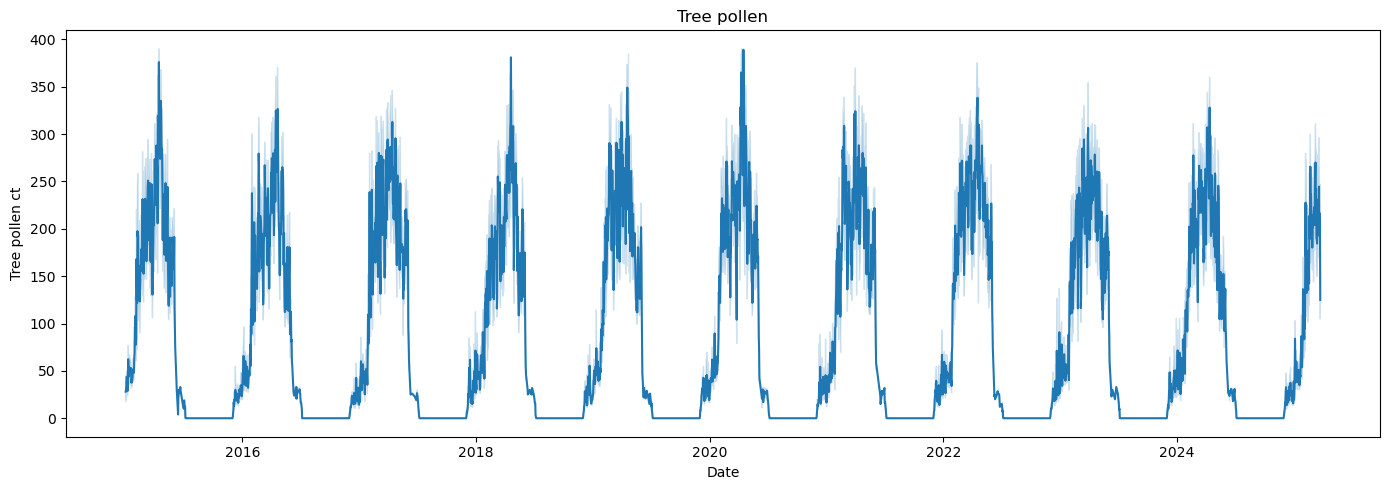

In [21]:
plt.figure(figsize=(14, 5))
sns.lineplot(x='createdAt', y='Count.tree_pollen', data=df)
plt.title("Tree pollen")
plt.xlabel("Date")
plt.ylabel("Tree pollen ct")
plt.tight_layout()
plt.show()

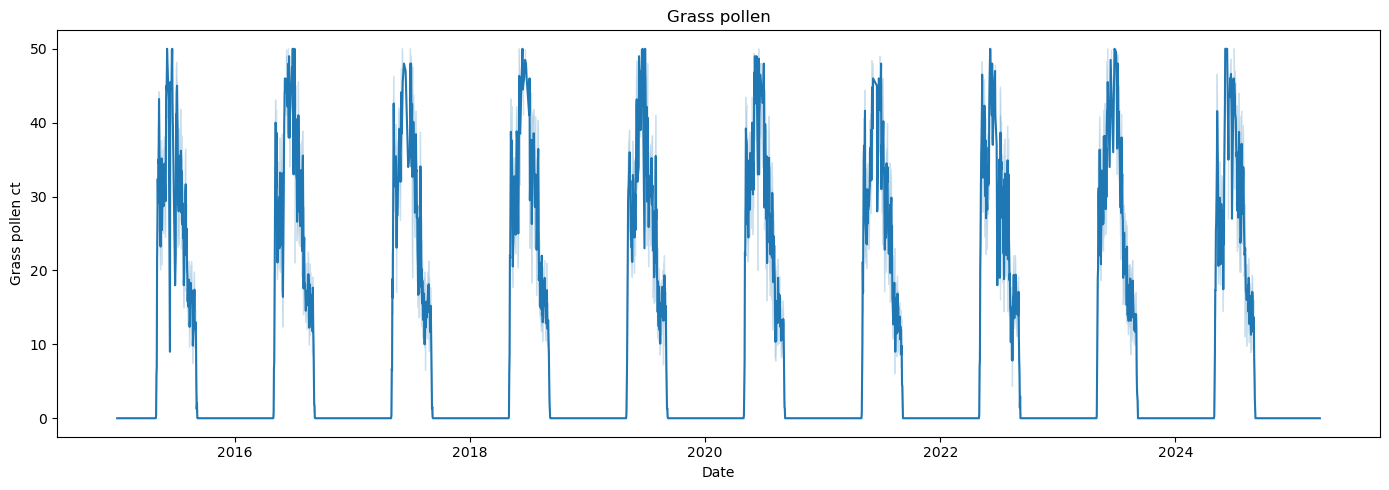

In [22]:
plt.figure(figsize=(14, 5))
sns.lineplot(x='createdAt', y='Count.grass_pollen', data=df)
plt.title("Grass pollen")
plt.xlabel("Date")
plt.ylabel("Grass pollen ct")
plt.tight_layout()
plt.show()

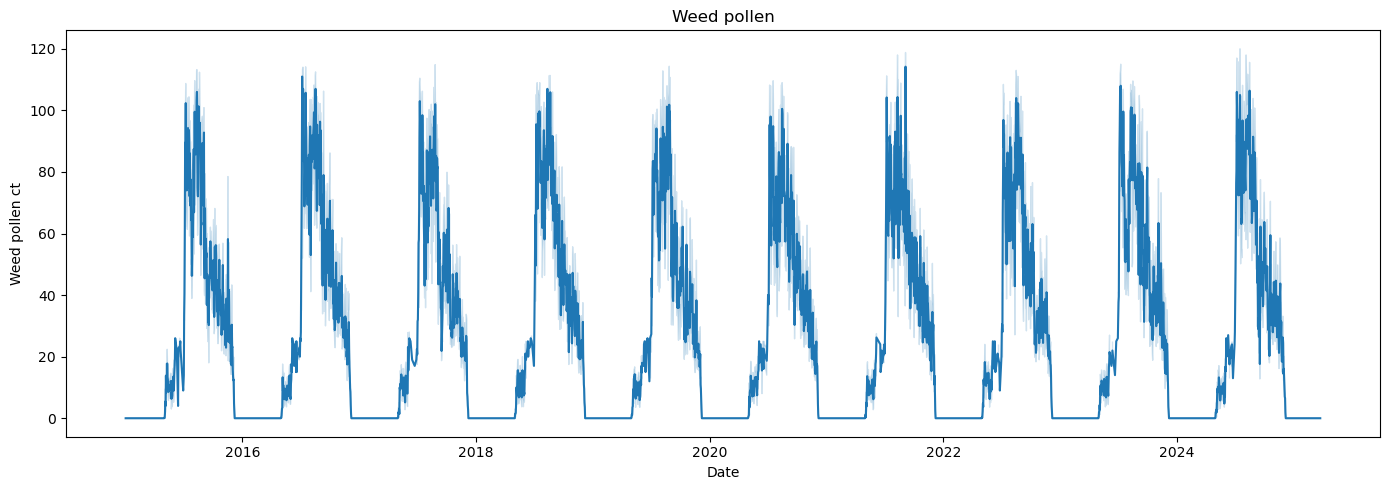

In [23]:
plt.figure(figsize=(14, 5))
sns.lineplot(x='createdAt', y='Count.weed_pollen', data=df)
plt.title("Weed pollen")
plt.xlabel("Date")
plt.ylabel("Weed pollen ct")
plt.tight_layout()
plt.show()

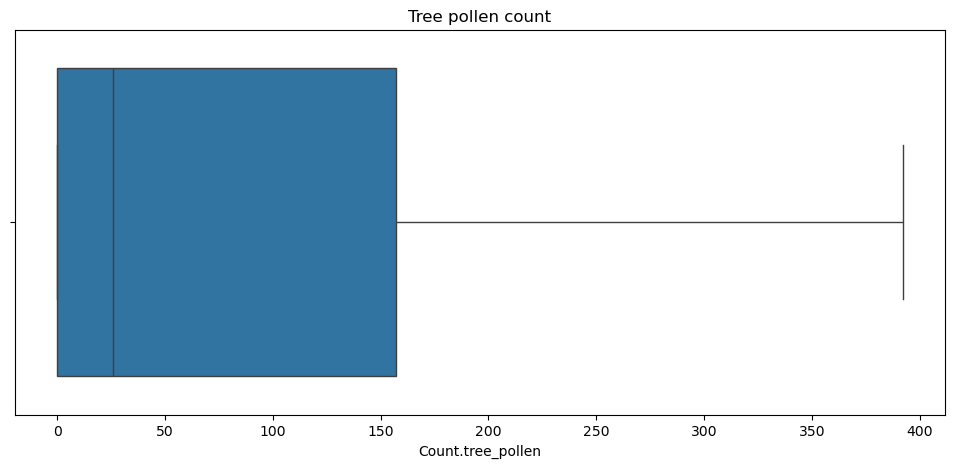

In [24]:
plt.figure(figsize=(12, 5))
sns.boxplot(x=df['Count.tree_pollen'])
plt.title("Tree pollen count")
plt.show()

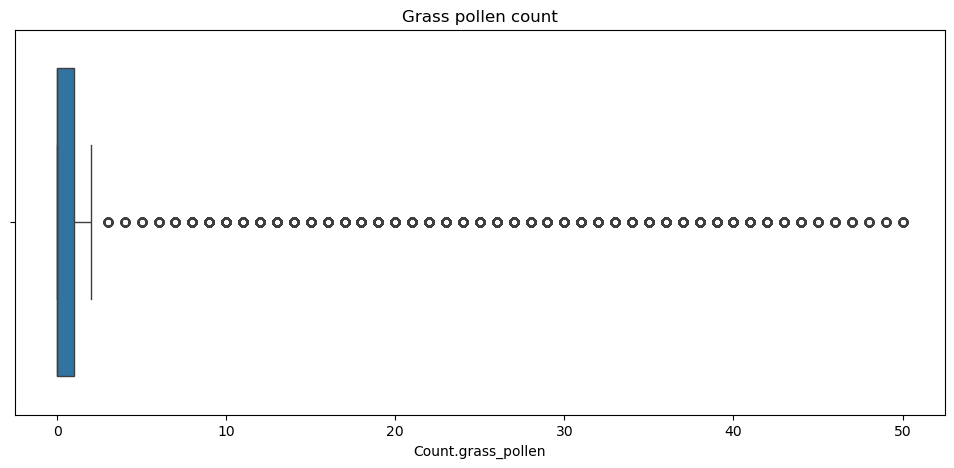

In [25]:
plt.figure(figsize=(12, 5))
sns.boxplot(x=df['Count.grass_pollen'])
plt.title("Grass pollen count")
plt.show()

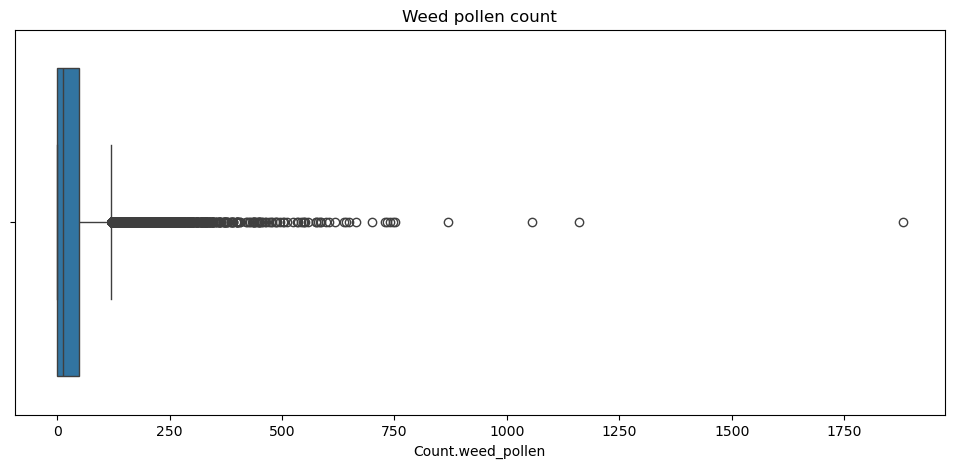

In [18]:
plt.figure(figsize=(12, 5))
sns.boxplot(x=df['Count.weed_pollen'])
plt.title("Weed pollen count")
plt.show()

In [26]:
q1 = df.quantile(0.25)
q3 = df.quantile(0.75)
iqr = q3 - q1

print(iqr)


df = df[~((df < (q1 - 1.5 * iqr)) | (df > (q3 + 1.5 * iqr))).any(axis=1)]
print(df.shape)

Count.tree_pollen                  157.0
Count.grass_pollen                   1.0
Count.weed_pollen                   39.0
lat                             3.670957
lng                             3.029658
time                         162777600.0
createdAt             1884 days 00:00:00
dtype: object
(29810, 7)


In [ ]:
#grouped by lat lng
#reample from daily to montlhy
#plot for each region on a single graph